# 02. Pulizia, divisione dei dati e primo modello (baseline)
**Progetto:** HelpDesk AI · **Passo 1:** dati

In questo notebook applichiamo le decisioni nate dal notebook 01

## Cosa faremo:
1. Import e configurazione
2. Caricamento e pulizia difensiva
3. Trovare i quasi-duplicati
4. Dividere i dati in train, validation e test
5. Salvare la divisione
6. Un riferimento minimo: il modello "stupido"
7. Il primo modello: TF-IDF + regressione logistica
8. Quanto conta il *data leakage*? (esperimento)
9. Esperimenti di preprocessing
10. Cosa ha imparato il modello
11. Analisi degli errori
12. Salvataggio del modello
13. Riepilogo

# 1. Import e configurazione
Rispetto al notebook 1 aggiungiamo:
| Strumento | A cosa serve |
|---|---|
| `NearestNeighbors` | trovare i ticket molto simili tra loro (quasi-duplicati) |
| `scipy.sparse.csgraph.connected_components` | unire i ticket simili in **gruppi** |
| `StratifiedGroupKFold` | dividere i dati tenendo insieme i gruppi e mantenendo le proporzioni delle categorie |
| `Pipeline` | unire TF-IDF e classificatore in un unico oggetto |
| `DummyClassifier` | un modello "finto" che fa da riferimento minimo |
| `LogisticRegression` | il nostro primo classificatore |
| metriche di `sklearn.metrics` | accuratezza, F1, report per categoria, matrice di confusione |
| `joblib` | salvare il modello su disco |


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.sparse.csgraph import connected_components

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

In [2]:
# --- Riproducibilità ---
RANDOM_STATE = 42

# --- Percorsi ---
PROJECT_DIR = Path("..")
DATA_PATH = PROJECT_DIR / "data" / "raw" / "all_tickets_processed_improved_v3.csv"
SPLIT_PATH = PROJECT_DIR / "data" / "processed" / "tickets_split.csv"
MODELS_DIR = PROJECT_DIR / "models"

# --- Colonne ---
TEXT_COL = "Document"
LABEL_COL = "Topic_group"

# --- Stile dei grafici ---
TESTO_SECONDARIO = "#52514e"
GRIGLIA = "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIGLIA,
    "xtick.color": TESTO_SECONDARIO,
    "ytick.color": TESTO_SECONDARIO,
})
pd.set_option("display.max_colwidth", 200)

# 2. Caricamento e pulizia
Anche se nel notebook 01 non abbiamo trovato valori mancanti, testi vuoti, duplicati o conflitti scriviamo comunque i passaggi di pulizia per:
- Robustezza: se il dataset venisse aggiornato con righe sporche, il notebook le gestirebbe da solo
- Trasparenza: stampiamo quante righe rimuove ogni passaggi

In [3]:
df = pd.read_csv(DATA_PATH)
n_iniziale = len(df)
print(f"Righe caricate: {n_iniziale}")

def rimuovi(df_corrente, maschera_da_tenere, descrizione):
    # Applica un filtro e stampa quante righe ha rimosso
    prima = len(df_corrente)
    df_nuovo = df_corrente[maschera_da_tenere].copy()
    print(f"    {descrizione:<40} -{prima - len(df_nuovo)}")
    return df_nuovo

df = rimuovi(df, df[TEXT_COL].notna(), "testo mancante")
df = rimuovi(df, df[LABEL_COL].notna(), "categoria mancante")
df[TEXT_COL] = df[TEXT_COL].str.strip()
df[LABEL_COL] = df[LABEL_COL].str.strip()
df = rimuovi(df, df[TEXT_COL] != "", "testo vuoto")
df = rimuovi(df, ~df.duplicated(), "duplicati esatti")
in_conflitto = df.groupby(TEXT_COL)[LABEL_COL].transform("nunique") > 1
df = rimuovi(df, ~in_conflitto, "testi con categorie in conflitto")

df = df.reset_index(drop=True)
print(f"\nRighe finali: {len(df)} (rimosse {n_iniziale - len(df)})")

Righe caricate: 47837
    testo mancante                           -0
    categoria mancante                       -0
    testo vuoto                              -0
    duplicati esatti                         -0
    testi con categorie in conflitto         -0

Righe finali: 47837 (rimosse 0)


# 3. Trovare i quasi-duplicati
Molti ticket sono email standard che potrebbero differire anche per un solo nome o una data. Se dividiamo i dati a caso, un ticket può finire nel train ed il suo "quasi-duplicato" nel test.

La soluzione: raggruppare e dividere per gruppi

1. Rappresentiamo ogni ticket con TF-IDF
2. Misuriamo la similarità del coseno tra ticket (1 se due testi usano le stesse parole, 0 se non hanno nulla in comune)
3. Colleghiamo i tikcet con similarità ≥ 0,9 (soglia usata anche in analisi pubblicate su questo dataset)
4. Ogni insieme di ticket collegati diventa un gruppo
5. Nello split, un gruppo intero finisce in un solo insieme (train, validation o test)

In [4]:
%%time 
# Per calcolare quanto impiega la cella

SOGLIA_SIMILARITA = 0.9

# 1. Rappresen0tazione TF-IDF di tutti i ticket
tfidf_gruppi = TfidfVectorizer(min_df=2)
X_tutti = tfidf_gruppi.fit_transform(df[TEXT_COL])

# 2. Per ogni ticket cerchiamo i vicini entro una certa distanza.
# Distanza del coseno = 1 - similarità, quindi similarità >=0.9 vuol dire distanza <=0.1
# Per confrontare tutti i ticket usiamo working_memory=256, così scikit-learn lo fa a blocchi di 256 MB (eseguibile anche su PC con poca RAM)
import sklearn
with sklearn.config_context(working_memory=256):
    vicini = NearestNeighbors(metric="cosine", radius=1 - SOGLIA_SIMILARITA, algorithm="brute")
    vicini.fit(X_tutti)
    grafo = vicini.radius_neighbors_graph(X_tutti, mode="connectivity")

# 3. Ogni componente collegato del grafo è un gruppo di ticket simili
n_gruppi, etichetta_gruppo = connected_components(grafo, directed=False)
df["gruppo"] = etichetta_gruppo

dimensioni = df["gruppo"].value_counts()
nei_gruppi = dimensioni[dimensioni > 1]
print(f"Gruppi totali:                          {n_gruppi}")
print(f"Gruppi con più di un ticket:            {len(nei_gruppi)}")
print(f"Ticket che hanno almeno un 'gemello':   {nei_gruppi.sum()} ({nei_gruppi.sum() / len(df) * 100:.1f}%)")
print(f"Gruppo più grande:                      {dimensioni.max()} ticket")

Gruppi totali:                          42230
Gruppi con più di un ticket:            1643
Ticket che hanno almeno un 'gemello':   7250 (15.2%)
Gruppo più grande:                      648 ticket
CPU times: total: 33.1 s
Wall time: 33.8 s


In [5]:
# Mostriamo alcuni ticket del gruppo più grande
gruppo_grande = dimensioni.index[0]
display(df.loc[df['gruppo'] == gruppo_grande, [TEXT_COL, LABEL_COL]].head(5))

# Quante categorie diverse ci sono dentro ai gruppi? 
categorie_per_gruppo = df[df['gruppo'].isin(nei_gruppi.index)].groupby('gruppo')[LABEL_COL].nunique()
print(f"Gruppi con ticket di categorie diverse: {(categorie_per_gruppo > 1).sum()} su {len(nei_gruppi)}")

,Document,Topic_group
25,new purchase po purchase po dear purchased has please log allocation after item please take consideration mandatory receipts section order receive item ordered how video link please receipt number...,Purchase
32,new purchase po purchase po dear purchased please log allocation after item please take consideration mandatory receipts section order receive item ordered how video link please receipt number ite...,Purchase
36,new purchase po purchase po dear purchased has please log allocation please log retrieve old device after receive item please take consideration mandatory receipts section order make receipt item ...,Purchase
41,new purchase po purchase po dear purchased matte display please log allocation after receive item please take consideration mandatory receipts section order make receipt item ordered how video lin...,Purchase
53,new purchase po purchase po dear purchased monitor please log allocation after item please take consideration mandatory receipts section order receive item ordered how video link please receipt nu...,Purchase


Gruppi con ticket di categorie diverse: 171 su 1643


# Osservazioni (parte 3)
- **7.250 ticket (15,2%)** hanno almeno un quasi-gemello, in **1.643 gruppi**: in linea con le analisi pubblicate
  su questo dataset (~7.200 ticket in ~1.640 gruppi con la stessa soglia). Uno split casuale avrebbe causato data leakage.
- Il gruppo più grande ha **648 ticket**: tutte email standard di ordini d'acquisto (Purchase), cioè più di un quarto
  della categoria. Le prestazioni su Purchase saranno in parte "facilitate" dal testo standard.
- **171 gruppi su 1.643** contengono categorie diverse: in parte rumore nelle etichette, in parte "effetto catena"
  del raggruppamento (A simile a B, B simile a C).

# 4. Divisione dei dati in Train, Validation e Test
Train 80%
Validation 10%
Test 10%

Per dividere usiamo **`StratifiedGroupKFold`** che rispetta due vincoli insieme:
- **stratificato**: ogni insieme ha più o meno le stesse proporzioni di categorie del dataset
- **per gruppi**: i ticket dello stesso gruppo restano nello stesso insieme

Per evitare che un gruppo grande finisca nel test, proviamo tutte e 10 le parti come possibili e teniamo quella con le proporzioni di categorie più vicine a quelle del dataset completo. Così i gruppi più grandi finiranno nel train. Faremo poi lo stesso per la validation.

In [6]:
def scegli_divisione_bilanciata(dati, n_splits):
    divisore = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    proporzioni_totali = dati[LABEL_COL].value_counts(normalize=True)

    migliore, scarto_minimo = None, np.inf
    for idx_grande, idx_piccolo in divisore.split(dati, dati[LABEL_COL], groups=dati['gruppo']):
        proporzioni = dati[LABEL_COL].iloc[idx_piccolo].value_counts(normalize=True)
        proporzioni = proporzioni.reindex(proporzioni_totali.index, fill_value=0)
        scarto = (proporzioni - proporzioni_totali).abs().max() # differenza peggiore tra le categorie
        if scarto < scarto_minimo:
            migliore, scarto_minimo = (idx_grande, idx_piccolo), scarto
    return migliore, scarto_minimo

# --- Primo taglio (TEST) ---
(idx_resto, idx_test), scarto_test = scegli_divisione_bilanciata(df, n_splits=10)
df_resto = df.iloc[idx_resto]

# --- Secondo taglio (VALIDATION) ---
(idx_train_rel, idx_val_rel), scarto_val = scegli_divisione_bilanciata(df_resto, n_splits=9)
print(f"Scarto massimo di proporzione: test {scarto_test * 100:.1f} punti, validation {scarto_val * 100:.1f} punti")

# Gli indici del secondo taglio sono relativi a df_resto: li riportiamo a df
idx_train = df_resto.index[idx_train_rel]
idx_val = df_resto.index[idx_val_rel]

df["split"] = ""
df.loc[idx_train, "split"] = "train"
df.loc[idx_val, "split"] = "val"
df.loc[df.index[idx_test], "split"] = "test"

print(df["split"].value_counts())

Scarto massimo di proporzione: test 0.9 punti, validation 1.0 punti
split
train    38359
test      4739
val       4739
Name: count, dtype: int64


In [7]:
# --- Controllo 1: nessun gruppo deve comparire in due insiemi diversi ---
insiemi_per_gruppo = df.groupby("gruppo")["split"].nunique()
assert (insiemi_per_gruppo == 1).all(), "Errore: alcuni gruppi sono divisi tra più insiemi!"
print("OK: ogni gruppo si trova in un solo insieme.")

# --- Controllo 2: le proporzioni delle categorie sono simili? ---
proporzioni = pd.crosstab(df[LABEL_COL], df["split"], normalize="columns").mul(100).round(1)
proporzioni["dataset completo"] = (df[LABEL_COL].value_counts(normalize=True) * 100).round(1)
display(proporzioni[["train", "val", "test", "dataset completo"]])

OK: ogni gruppo si trova in un solo insieme.


split,train,val,test,dataset completo
Topic_group,,,,
Access,14.9,15.0,15.0,14.9
Administrative rights,3.7,3.7,3.7,3.7
HR Support,22.8,23.0,23.0,22.8
Hardware,28.4,28.7,28.7,28.5
Internal Project,4.4,4.5,4.5,4.4
Miscellaneous,14.7,14.9,14.9,14.8
Purchase,5.4,4.3,4.3,5.2
Storage,5.8,5.8,5.8,5.8


# 5. Salvataggio divisione
Salviamo il dataset con le colonne **gruppo** e **split** in data/processe/. In questo modo, nei prossimi passi, utilizzeremo la stessa divisione

In [8]:
df.to_csv(SPLIT_PATH, index=False)
print("Salvato:", SPLIT_PATH.resolve())

# Per comodità per il resto del notebook
train = df[df["split"] == "train"]
val = df[df["split"] == "val"]
X_train, y_train = train[TEXT_COL], train[LABEL_COL]
X_val, y_val = val[TEXT_COL], val[LABEL_COL]
# Il TEST non sarà necessario per ora

Salvato: C:\Users\logic\Desktop\PROGRAMMAZIONE\GitHub\Capstone_Project\data\processed\tickets_split.csv


# 6. Modello Dummy
Prima di addestrare un modello vero, misuriamo cosa ottiene un modello che **non impara nulla**: DummyClassifier(strategy='most_frequent') risponde sempre con la categoria più frequente.

In [9]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
pred_dummy = dummy.predict(X_val)

print(f"Modello Dummy (risponde sempre '{dummy.classes_[dummy.class_prior_.argmax()]}')")
print(f"Accuratezza: {accuracy_score(y_val, pred_dummy):.3f}")
print(f"F1 macro: {f1_score(y_val, pred_dummy, average='macro'):.3f}")

Modello Dummy (risponde sempre 'Hardware')
Accuratezza: 0.287
F1 macro: 0.056


# 7. Primo modello: TF-IDF + regressione logistica
### Come funzione:
1. **TF-IDF** trasforma ogni ticket in un vettore di numeri: un valore per ogni parola del vocabolario, alto se la parola è importante per quel ticket.
2. La **regressione logistica** impara un peso per ogni parola e per ogni categoria e combina i pesi per calcolare la probabilità che il ticket appartenga a ciascuna categoria.

### Perché questo modello?
- È veloce: si addestra in pochi secondi e si possono fare molteplici esperimenti,
- È forte sul testo,
- È interpretabile: possiamo leggere quali parole spingono verso ogni categoria,

### Le impostazioni

| Parametro | Valore | Perché |
|---|---|---|
| `min_df=5` | ignora le parole presenti in meno di 5 ticket | toglie le parole rarissime (il 22% del vocabolario compare una sola volta) |
| `class_weight="balanced"` | errori sulle categorie piccole pesano di più | compensa lo sbilanciamento 7,7 a 1 |
| `max_iter=1000` | più iterazioni dell'ottimizzatore | con il valore predefinito (100) potrebbe non arrivare a convergenza |

In [10]:
def crea_modello(stop_words=None):
    # Restituisce una pipeline TF-IDF + regressione logistica
    return Pipeline([
        ("tfidf", TfidfVectorizer(min_df=5, stop_words=stop_words)),
        ("classificatore", LogisticRegression(class_weight="balanced", max_iter=1000)),
    ])

def valuta(modello, X, y, nome):
    # Calcola le metriche principali e restituisce un dizionario
    pred = modello.predict(X)
    return {
        "modello": nome,
        "accuratezza": round(accuracy_score(y, pred), 4),
        "F1 macro": round(f1_score(y, pred, average="macro"), 4),
    }

In [11]:
%%time
baseline = crea_modello()
baseline.fit(X_train, y_train)

risultato_baseline = valuta(baseline, X_val, y_val, "TF-IDF + regressione logistica")
print(risultato_baseline)

{'modello': 'TF-IDF + regressione logistica', 'accuratezza': 0.8432, 'F1 macro': 0.843}
CPU times: total: 2.88 s
Wall time: 2.9 s


### Report per categoria

Per ogni categoria:
- **precision:** dei ticket che il modello ha assegnato a quella categoria, quanti erano giusti;
- **recall:** dei ticket che appartengono a quella categoria, quanti il modello ha trovato;
- **f1-score:** media armonica di precision e recall, alta solo se entrambe sono alte;
- **support:** quanti ticket di quella categoria ci sono nella validation.

In [12]:
pred_val = baseline.predict(X_val)
print(classification_report(y_val, pred_val, digits=3))

                       precision    recall  f1-score   support

               Access      0.915     0.879     0.897       713
Administrative rights      0.654     0.869     0.746       176
           HR Support      0.870     0.803     0.835      1092
             Hardware      0.847     0.817     0.832      1361
     Internal Project      0.787     0.925     0.850       212
        Miscellaneous      0.798     0.853     0.825       706
             Purchase      0.884     0.866     0.875       202
              Storage      0.852     0.917     0.883       277

             accuracy                          0.843      4739
            macro avg      0.826     0.866     0.843      4739
         weighted avg      0.847     0.843     0.844      4739



### Matrice di confusione

Ogni riga è la categoria **reale**, ogni colonna quella **prevista**. Normalizziamo per riga (normalize='true'): ogni cella mostra la quota dei ticket di quella categoria che il modello ha messo in ciascuna colonna. La diagonale è la quota dei ticket calssificati correttamente (recall); fuori dalla diagonale ci sono le confusioni.

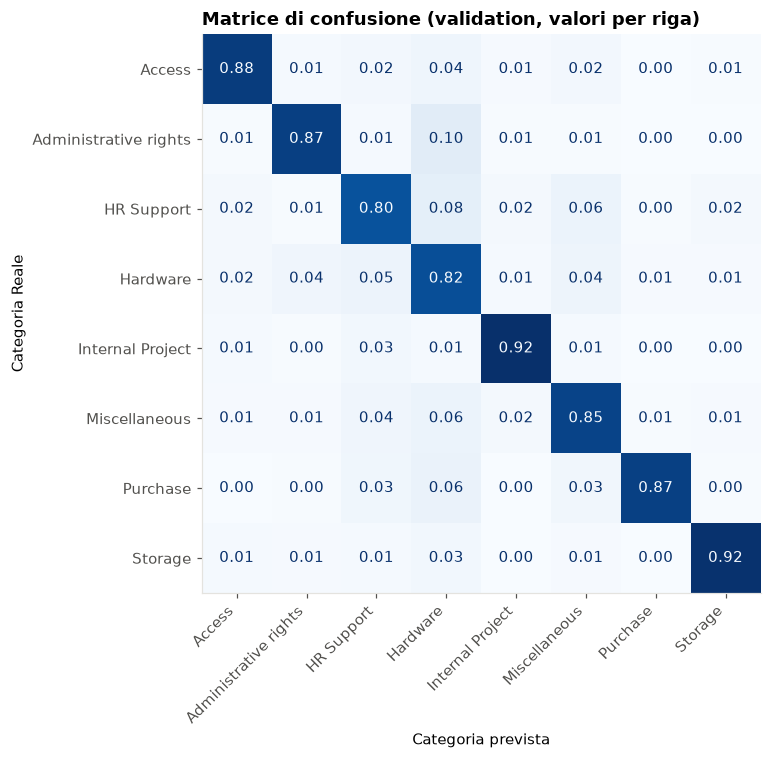

In [13]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_val, pred_val, normalize='true', values_format='.2f',
    cmap="Blues", xticks_rotation=45, colorbar=False, ax=ax,
)
ax.set_title("Matrice di confusione (validation, valori per riga)")
ax.set_xlabel("Categoria prevista")
ax.set_ylabel("Categoria Reale")
plt.setp(ax.get_xticklabels(), ha='right')
plt.tight_layout()
plt.show()

### Osservazioni (parte 7)
- **F1 macro 0,843** e accuratezza 0,843 (dummy: 0,056). Addestramento in circa 3 secondi.
  In linea con analisi pubblicate (~0,85 con split casuale): il valore leggermente più basso è coerente con lo split per gruppi.
- Categorie migliori: Access (0,897), Storage (0,883), Purchase (0,875). Peggiore: **Administrative rights (0,746)**,
  con recall alto (0,869) e precision bassa (0,654): effetto di `class_weight="balanced"`, falsi positivi soprattutto da Hardware.
- Confusioni previste nel notebook 01:
  - **Hardware <-> Administrative rights: confermata** (10% di Administrative rights finisce in Hardware);
  - **Access <-> Storage: non confermata** (1%): le parole caratteristiche bastano a distinguerle.
- **Hardware fa da "calamita"**: riceve ticket da quasi tutte le categorie (Administrative rights 10%, HR 8%, Misc e Purchase 6%).
- Precision macro (0,826) < recall macro (0,866): compromesso dovuto ai pesi delle classi.

# 8. Esperimento: *data leakage*

Valutiamo se il lavoro fatto per dividere i dati per gruppi è realmente necessario.

Prendiamo i ticket dei train e validation e li dividiamo in due modi, con le stesse proporzioni:
- A -> Split casuale stratificato (`train_test_split`) che ignora i quasi-duplicati;
- B -> Split per gruppi

Addestriamo lo stesso modello e confrontiamo F1 macro

In [14]:
%%time
sviluppo = df[df["split"].isin(["train", "val"])]
quota_val = len(val) / len(sviluppo)

# A -> Split casuale stratificato
tr_a, va_a = train_test_split(sviluppo, test_size=quota_val, stratify=sviluppo[LABEL_COL], random_state=RANDOM_STATE)
modello_a = crea_modello().fit(tr_a[TEXT_COL], tr_a[LABEL_COL])
f1_a = f1_score(va_a[LABEL_COL], modello_a.predict(va_a[TEXT_COL]), average="macro")

# B -> Split per gruppi (il modello è il baseline già addestrato)
f1_b = risultato_baseline["F1 macro"]

print(f"F1 macro con split casuale: {f1_a:.4f}")
print(f"F1 macro con split per gruppi: {f1_b:.4f}")
print(f"Differenza (ottimismo dello split casuale): {f1_a - f1_b:+.4f}")

F1 macro con split casuale: 0.8534
F1 macro con split per gruppi: 0.8430
Differenza (ottimismo dello split casuale): +0.0104
CPU times: total: 2.48 s
Wall time: 2.46 s


### Osservazioni (parte 8)

- Split casuale: F1 macro **0,8534**; split per gruppi: **0,8430**. Lo split casuale è **ottimista di circa 1 punto**.
- Il valore con split casuale coincide con quello riportato da analisi pubblicate (~0,85): la differenza
  con il mio baseline dipende dal metodo di valutazione, non dal modello.
- Un punto è dello stesso ordine delle differenze tra i modelli che confronterò: con uno split casuale
  rischierei di scegliere il modello che sfrutta i quasi-duplicati invece di quello che generalizza meglio.
- Limite: confronto basato su una sola divisione per tipo; la cross-validation darà una stima più solida.

# 9. Esperimenti di preprocessing

Nel notebook 01 abbiamo visto che i testi contengono parti che non riguardano il problema: stopword, saluti, intestazioni delle mail ecc.

Confrontiamo quattro versioni, cambiando solo la lista di parole che il TF-IDF ignora:

| Versione | Parole ignorate |
|---|---|
| A. testo originale | nessuna |
| B. senza stopword | lista standard inglese di scikit-learn |
| C. senza "rumore email" | la nostra lista: saluti, intestazioni, giorni, mesi |
| D. senza stopword né rumore email | B + C |

Cambiamo una cosa per volta confrontandola sempre sulla validation

In [16]:
SALUTI = ["hi", "hello", "hey", "dear", "please", "thanks", "thank", "regards",
          "kind", "best", "cheers", "sincerely"]
INTESTAZIONI_EMAIL = ["re", "fw", "fwd", "sent", "subject", "cc", "pm", "am"]
GIORNI = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]
MESI = ["january", "february", "march", "april", "may", "june", "july",
        "august", "september", "october", "november", "december"]

RUMORE_EMAIL = sorted(set(SALUTI + INTESTAZIONI_EMAIL + GIORNI + MESI))
STOPWORD_INGLESI = sorted(ENGLISH_STOP_WORDS)
STOPWORD_E_RUMORE = sorted(set(STOPWORD_INGLESI) | set(RUMORE_EMAIL))

print(f"Parole nella lista 'rumore email': {len(RUMORE_EMAIL)}")
print(f"Stopword inglesi da scikit-learn: {len(STOPWORD_INGLESI)}")

Parole nella lista 'rumore email': 39
Stopword inglesi da scikit-learn: 318


In [17]:
%%time
versioni = {
    "A. testo originale": None,
    "B. senza stopword": STOPWORD_INGLESI,
    "C. senza rumore email": RUMORE_EMAIL,
    "D. senza stopword né rumore email": STOPWORD_E_RUMORE,
}

modelli = {}
risultati = []
for nome, lista in versioni.items():
    modello = crea_modello(stop_words=lista).fit(X_train, y_train)
    modelli[nome] = modello
    risultati.append(valuta(modello, X_val, y_val, nome))

tabella_risultati = pd.DataFrame(risultati).set_index("modello")
display(tabella_risultati)

,accuratezza,F1 macro
modello,,
A. testo originale,0.8432,0.8430
B. senza stopword,0.8369,0.8389
C. senza rumore email,0.8449,0.8453
D. senza stopword né rumore email,0.8346,0.8366


CPU times: total: 8.7 s
Wall time: 8.61 s


In [18]:
VERSIONE_SCELTA = tabella_risultati["F1 macro"].idxmax()

modello_scelto = modelli[VERSIONE_SCELTA]
pred_val = modello_scelto.predict(X_val)
print("Versione scelta: ", VERSIONE_SCELTA)
print(tabella_risultati.loc[VERSIONE_SCELTA].to_dict())

Versione scelta:  C. senza rumore email
{'accuratezza': 0.8449, 'F1 macro': 0.8453}


### Osservazioni (parte 9)

- **Togliere le stopword peggiora** (B e D sono le peggiori): la lista inglese di scikit-learn contiene parole utili
  in ambito IT (*up, down, on, off, back* per *log in, set up, back up*; *full, empty* per Storage; *fill* per i moduli HR;
  le negazioni). Inoltre il TF-IDF riduce già il peso delle parole comuni tramite l'IDF.
- **Togliere saluti, intestazioni e date migliora** (+0,002): quelle parole non portavano informazione.

# 10. Cosa ha imparato il modello

La regressione logistica assegna un valore ad ogni parola per ogni categoria: più è alto, più quella parola spinge il ticket verso quella categoria.

Leggiamo le parole con i coefficienti più alti per capire se sono parole sensate e se compaiono saluti, firme o parole casuali.

In [21]:
vocabolario = modello_scelto.named_steps["tfidf"].get_feature_names_out()
classificatore = modello_scelto.named_steps["classificatore"]

righe = []
for i, categoria in enumerate(classificatore.classes_):
    migliori = classificatore.coef_[i].argsort()[::-1][:12]
    righe.append({"categoria": categoria,
                  "parole con peso più alto": ", ".join(vocabolario[migliori])})
display(pd.DataFrame(righe))

,categoria,parole con peso più alto
0,Access,"confluence, user, password, account, license, card, repository, git, accounts, locked, create, cards"
1,Administrative rights,"outlook, upgrade, issues, windows, install, software, exchange, version, update, assets, again, not"
2,HR Support,"starter, time, leave, error, oracle, annual, access, submit, leaver, timecard, to, transfer"
3,Hardware,"laptop, monitor, room, phone, meeting, connection, cable, ram, certificate, calls, backpack, call"
4,Internal Project,"code, project, codes, pipeline, setup, pas, pipelines, pipe, opportunity, unknown, import, known"
5,Miscellaneous,"change, approval, approve, groups, add, ticket, tickets, name, approver, approved, contract, owner"
6,Purchase,"purchase, po, installation, administrator, device, log, order, devices, allocation, receipt, items, item"
7,Storage,"folder, mailbox, wants, storage, shared, folders, mailboxes, files, size, permissions, file, increase"


### Osservazioni (parte 10)

- Con la versione C le parole con peso più alto sono quasi tutte di **contenuto**: spariti saluti, intestazioni
  e quasi tutte le parole di stile (*you, with, sent*) viste nel notebook 01.
- Categorie coerenti: Access (password, account, locked, license, git, card), Hardware (laptop, monitor, cable,
  connection, ram, meeting room), Storage (mailbox, folder, shared, size, increase), HR Support (starter, leaver,
  leave, timecard, oracle), Internal Project (code, project, pipeline), Miscellaneous (approval, groups, owner).
- **Purchase** usa anche parole della firma (*administrator*) e dell'email standard (*log, allocation*):
  il modello ha imparato in parte il modulo. Da verificare con richieste di acquisto scritte liberamente.
- **Administrative rights** usa parole di malfunzionamento (*again, not, issues*): spiega la confusione con Hardware.
  La presenza di *not* conferma che togliere le stopword avrebbe eliminato informazione utile.

# 11. Analisi degli errori
Le metriche ci dicono *quanto* sbaglia il modello ma non *perché*. Leggiamo alcuni ticket classificati male vediamo se il ticket era chiaro ma ha sbagliato il modello, se è sbagliata l'etichetta o se è ambiguo perché magari contiene più problemi.

In [22]:
probabilità = modello_scelto.predict_proba(X_val)
sicurezza = probabilità.max(axis=1)

analisi = val[[TEXT_COL, LABEL_COL]].copy()
analisi["prevista"] = pred_val
analisi["sicurezza"] = sicurezza.round(2)
analisi["corretto"] = analisi[LABEL_COL] == analisi["prevista"]

print(f"Sicurezza media quando ha ragione: {analisi.loc[analisi['corretto'], 'sicurezza'].mean():.2f}")
print(f"Sicurezza media quando sbaglia:    {analisi.loc[~analisi['corretto'], 'sicurezza'].mean():.2f}")

Sicurezza media quando ha ragione: 0.80
Sicurezza media quando sbaglia:    0.50


In [24]:
errori = analisi[~analisi["corretto"]].copy()
errori[TEXT_COL] = errori[TEXT_COL].str.slice(0, 180)
print(f"Errori sulla validation: {len(errori)} su {len(analisi)}")
display(errori.sample(min(12, len(errori)), random_state=RANDOM_STATE)[[TEXT_COL, LABEL_COL, "prevista", "sicurezza"]])

Errori sulla validation: 735 su 4739


,Document,Topic_group,prevista,sicurezza
36265,system degraded on physical host degraded hi noticed physical host degraded host for for know you raise ticket for kind problem regards senior server infrastructure engineer infras,Hardware,Miscellaneous,0.31
1949,access for hi established link rights given certain resources within lead engineer did asking allow she exactly her name computer name her computer identifier printed label please,Miscellaneous,Hardware,0.31
18327,to tuesday march pm dear ask allocate he joining per contractual agreement assigned work were few persons recently left order other initiate thank mob,HR Support,Miscellaneous,0.27
13064,installation the memories friday pm upgrade has assigned hi got part memories arrived opening installing memories br tuesday pm re upgrade has assigned hello since has opened which,Hardware,Administrative rights,0.87
12804,de version tuesday july pm version hi received final version text work today please give estimate please assign queue thank best,Hardware,Administrative rights,0.38
10353,access request file thursday hello document layouts libraries action default help thank,Hardware,Storage,0.50
2176,addition report addition report hi please rise thank best regards engineer thursday december pm addition report la el thursday december pm addition report november pm addition repo,Hardware,Miscellaneous,0.35
14791,time card approval tuesday pm card issue importance high hi seems issues present yesterday evening received again attached please thank pm card issue importance high hi received ap,HR Support,Access,0.86
42674,faulty disk sent wednesday faulty disk importance high hi during routine checkup found was signaling fact one disk drives dead for tracking purposes please log ticket queue please,Miscellaneous,Hardware,0.69
11601,remove absence july re rejected hi please days holiday sheet thanks regards head testing mob july rejected hello everyone assistance required please let gladly help specialist ext,Hardware,HR Support,0.76


### Osservazioni (parte 11)

- Errori sulla validation: **735 su 4.739 (15,5%)**.
- Su 12 errori letti: ~5 del modello, ~3-4 etichette sbagliate (in 3 casi il modello ha dato la risposta più sensata,
  es. disco guasto etichettato Miscellaneous, ferie etichettate Hardware), ~3-4 ticket ambigui o frammentati.
- Gli errori con sicurezza alta nascono da **parole con due significati**: *install* (software vs RAM) e
  *card* (badge vs time card). Il modello guarda le parole singolarmente.
- **Sicurezza media: 0,80 quando ha ragione, 0,50 quando sbaglia.** Nell'app useremo una soglia:
  sotto la soglia il chatbot chiede più dettagli prima di classificare.

# 12. Salvataggio modello

Salviamo il modello con `joblib`, salviamo anche le liste e i risultati che useremo per confrontare i modelli nei prossimi passi.

In [25]:
MODELS_DIR.mkdir(exist_ok=True)

joblib.dump(modello_scelto, MODELS_DIR / "baseline_tfidf_logreg.joblib")

with open(MODELS_DIR / "liste_parole.json", "w", encoding="utf-8") as f:
    json.dump({"rumore_email": RUMORE_EMAIL}, f, indent=2)

tabella_risultati.to_csv(MODELS_DIR / "risultati_baseline.csv")
print("Salvati in: ", MODELS_DIR.resolve())

Salvati in:  C:\Users\logic\Desktop\PROGRAMMAZIONE\GitHub\Capstone_Project\models


# 13. Riepilogo

| Aspetto | Valore / osservazione |
|---|---|
| Righe rimosse dalla pulizia | **0** su 47.837: nessun mancante, testo vuoto, duplicato esatto o conflitto (confermato il notebook 01) |
| Ticket con almeno un quasi-gemello (%) | **7.250 (15,2%)** in 1.643 gruppi; gruppo più grande: 648 email standard di Purchase; 171 gruppi con categorie diverse |
| Dimensione di train / validation / test | **38.359 / 4.739 / 4.739** (80,2% / 9,9% / 9,9%), split stratificato per gruppi; scarto massimo di proporzione: 0,9 punti nel test, 1,0 nella validation |
| Modello dummy: accuratezza / F1 macro | 0,287 / **0,056** |
| Baseline (testo originale): accuratezza / F1 macro | 0,8432 / **0,8430** |
| Ottimismo dello split casuale (differenza di F1) | **+0,0104** (0,8534 contro 0,8430) |
| Versione di preprocessing scelta e motivo | **C. senza rumore email** (F1 macro **0,8453**): prestazioni pari o migliori, modello basato sul contenuto e più adatto alla chat. Togliere le stopword peggiora (−0,004 / −0,006) |
| Categorie migliori / peggiori | Migliori: Access (0,897), Storage (0,883), Purchase (0,875). Peggiore: Administrative rights (0,746; precision 0,654, recall 0,869) |
| Confusioni principali | Administrative rights -> Hardware (10%); Hardware fa da "calamita" per quasi tutte le categorie. Access <-> Storage solo 1% (ipotesi non confermata) |
| Errori: modello / etichetta / ambigui | 735 errori su 4.739 (15,5%). Su 12 letti: ~5 modello, ~3-4 etichetta sbagliata, ~3-4 ambigui. Errori sicuri causati da parole con due significati (*install*, *card*) |
| Sicurezza media: corretti vs errati | **0,80 vs 0,50** -> soglia per chiedere dettagli nell'app, da scegliere sul modello finale |